# Mecanismo de atención para series de tiempo
Objetivo: predecir el siguiente valor de una serie con tendencia, estacionalidad y ruido usando una LSTM con atención temporal. El notebook está listo para Google Colab.


## Concepto
La LSTM produce un estado por cada paso temporal. La atención calcula una puntuación para cada estado, aplica softmax y forma un contexto ponderado. Los pesos suman uno y muestran relevancia aprendida, no causalidad.


In [6]:
# Instala las dependencias necesarias cuando se ejecuta en Google Colab.
!pip -q install tensorflow scikit-learn pandas matplotlib



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
# Importa NumPy para cálculos numéricos y arreglos.
import numpy as np
# Importa Pandas para organizar los datos en tablas.
import pandas as pd
# Importa Matplotlib para crear gráficas.
import matplotlib.pyplot as plt
# Importa TensorFlow y Keras para construir redes neuronales.
import tensorflow as tf
# Importa el escalador que normaliza los datos.
from sklearn.preprocessing import MinMaxScaler
# Importa métricas para evaluar las predicciones.
from sklearn.metrics import mean_absolute_error, mean_squared_error
# Fija la semilla de NumPy para que el experimento sea reproducible.
np.random.seed(42); tf.keras.utils.set_random_seed(42)
# Define una función que genera la serie temporal de ejemplo.
def serie(n=1600):
    # Crea el índice temporal de la serie.
    t=np.arange(n)
    # Devuelve la serie con tendencia, estacionalidad y ruido.
    return pd.DataFrame({"tiempo":t,"valor":.0008*t+.55*np.sin(2*np.pi*t/50)+.2*np.sin(2*np.pi*t/12)+np.random.normal(0,.07,n)})
# Define una función que convierte la serie en ventanas de entrada y objetivos.
def ventanas(a,p=48):
    # Devuelve las ventanas X y los valores objetivo y como arreglos NumPy.
    return np.array([a[i-p:i] for i in range(p,len(a))])[...,None],np.array([a[i] for i in range(p,len(a))])


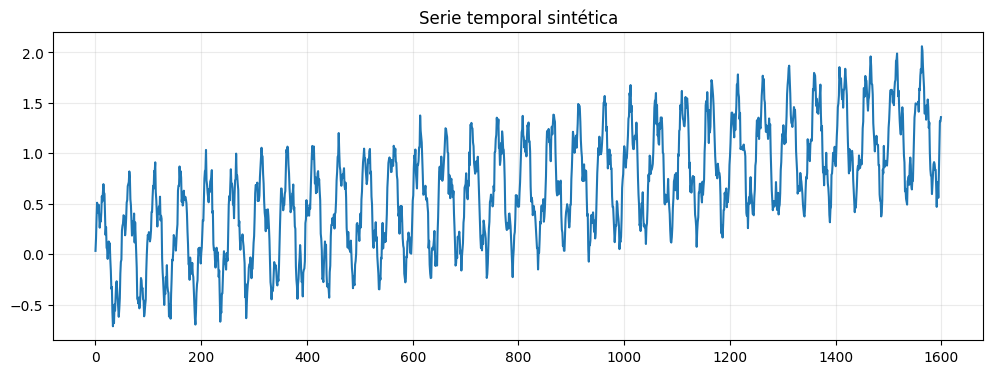

(1232, 48, 1) (320, 48, 1)


In [8]:
# Establece la longitud de cada ventana temporal.
PASOS=48
# Genera los datos que se utilizarán en el experimento.
datos=serie()
# Crea una figura para la visualización.
plt.figure(figsize=(12,4)); plt.plot(datos.tiempo,datos.valor); plt.title("Serie temporal sintética"); plt.grid(alpha=.25); plt.show()
# Calcula el punto de corte temporal entre entrenamiento y prueba.
limite=int(len(datos)*.8)
# Ajusta el escalador solo con entrenamiento para evitar fuga de información.
escalador=MinMaxScaler().fit(datos[["valor"]].iloc[:limite])
# Normaliza toda la serie usando los parámetros aprendidos en entrenamiento.
valores=escalador.transform(datos[["valor"]]).ravel()
# Construye las ventanas de entrada X y los objetivos y.
X,y=ventanas(valores,PASOS)
# Ajusta el corte porque las primeras observaciones forman la primera ventana.
corte=limite-PASOS
# Separa las ventanas y objetivos en conjuntos de entrenamiento y prueba.
X_train,X_test,y_train,y_test=X[:corte],X[corte:],y[:corte],y[corte:]
# Imprime una métrica, forma de arreglo o comprobación relevante.
print(X_train.shape,X_test.shape)


In [9]:
# Define una capa personalizada de atención temporal.
class AtencionTemporal(tf.keras.layers.Layer):
    # Inicializa las capas entrenables de la capa personalizada.
    def __init__(self,u=32,**kw):
        # Inicializa la clase base de Keras.
        super().__init__(**kw); self.a=tf.keras.layers.Dense(u,activation="tanh"); self.b=tf.keras.layers.Dense(1)
    # Define el cálculo que ejecuta la capa durante el paso hacia adelante.
    def call(self,h):
        # Normaliza las puntuaciones para obtener pesos de atención que suman uno.
        pesos=tf.nn.softmax(self.b(self.a(h)),axis=1)
        # Calcula el vector de contexto como suma ponderada de los estados.
        return tf.reduce_sum(pesos*h,axis=1),pesos
# Declara la entrada con una ventana y una variable por instante.
entrada=tf.keras.Input(shape=(PASOS,1))
# Procesa la secuencia y conserva un estado oculto por paso temporal.
h=tf.keras.layers.LSTM(64,return_sequences=True)(entrada)
# Aplica la capa de atención a los estados producidos por la LSTM.
contexto,pesos=AtencionTemporal(name="atencion")(h)
# Construye el modelo que conecta la entrada con la predicción.
modelo=tf.keras.Model(entrada,tf.keras.layers.Dense(1)(contexto))
# Configura el optimizador, la función de pérdida y la métrica de entrenamiento.
modelo.compile(optimizer=tf.keras.optimizers.Adam(1e-3),loss="mse",metrics=["mae"])
# Muestra la arquitectura y el número de parámetros del modelo.
modelo.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 48, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 48, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ atencion (AtencionTemporal)     │ [(None, 64), (None,    │         2,113 │
│                                 │ 48, 1)]                │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,074 (74.51 KB)

 Trainable params: 19,074 (74.51 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - loss: 0.0727 - mae: 0.2168 - val_loss: 0.0456 - val_mae: 0.1777
Epoch 2/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0342 - mae: 0.1602 - val_loss: 0.0379 - val_mae: 0.1641
Epoch 3/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0309 - mae: 0.1515 - val_loss: 0.0360 - val_mae: 0.1564
Epoch 4/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - loss: 0.0212 - mae: 0.1194 - val_loss: 0.0332 - val_mae: 0.1515
Epoch 5/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0154 - mae: 0.1008 - val_loss: 0.0228 - val_mae: 0.1264
Epoch 6/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0097 - mae: 0.0795 - val_loss: 0.0123 - val_mae: 0.0928
Epoch 7/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 0.0065 - mae: 0.0656 - val_loss: 0.0103 - val_mae: 0.0851
Epoch 8/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.0052 - mae: 0.0586 - val_loss: 0.0065 - val_mae: 0.0658
Epoch 9/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.004

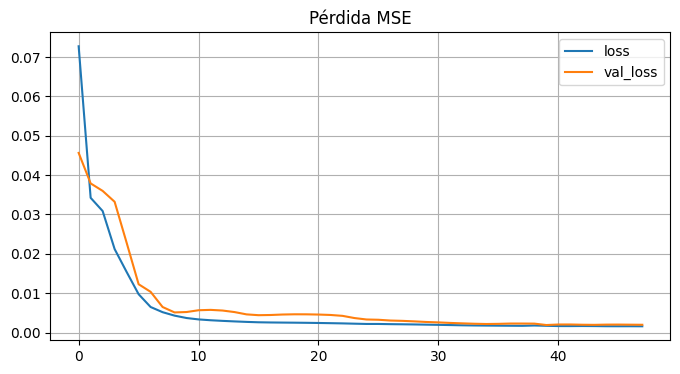

MAE: 0.09454868132171493 RMSE: 0.11739490627306595


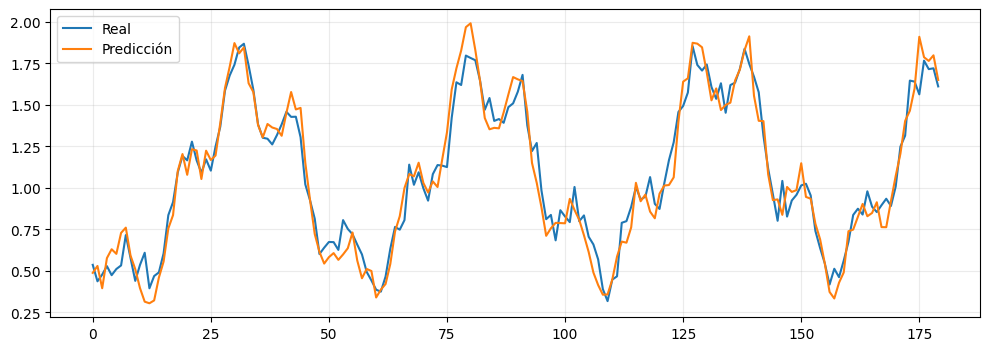

In [10]:
# Entrena el modelo y guarda las métricas de cada época.
historial=modelo.fit(X_train,y_train,validation_split=.15,epochs=60,batch_size=32,callbacks=[tf.keras.callbacks.EarlyStopping(patience=8,restore_best_weights=True)],verbose=1)
# Convierte el historial a tabla y grafica las pérdidas.
pd.DataFrame(historial.history)[["loss","val_loss"]].plot(figsize=(8,4),grid=True,title="Pérdida MSE"); plt.show()
# Genera predicciones normalizadas para el conjunto de prueba.
p=modelo.predict(X_test,verbose=0).ravel()
# Devuelve los valores reales a la escala original.
real=escalador.inverse_transform(y_test.reshape(-1,1)).ravel()
# Devuelve las predicciones a la escala original.
pred=escalador.inverse_transform(p.reshape(-1,1)).ravel()
# Calcula RMSE como la raíz cuadrada del error cuadrático medio.
rmse=np.sqrt(mean_squared_error(real,pred))
# Imprime una métrica, forma de arreglo o comprobación relevante.
print("MAE:",mean_absolute_error(real,pred),"RMSE:",rmse)
# Crea una figura para la visualización.
plt.figure(figsize=(12,4)); plt.plot(real[:180],label="Real"); plt.plot(pred[:180],label="Predicción"); plt.legend(); plt.grid(alpha=.25); plt.show()


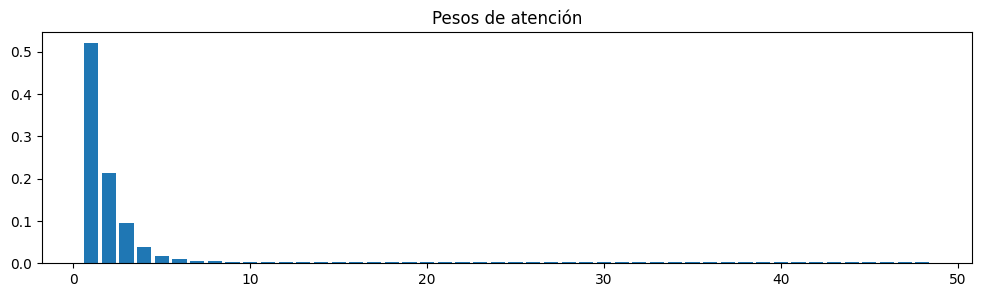

Suma de pesos: 0.99999994


In [11]:
# Crea un modelo auxiliar para extraer los pesos de atención.
extraer=tf.keras.Model(modelo.input,modelo.get_layer("atencion").output[1])
# Obtiene los pesos de atención de la primera ventana de prueba.
alpha=extraer.predict(X_test[:1],verbose=0).ravel()
# Crea una figura para la visualización.
plt.figure(figsize=(12,3)); plt.bar(np.arange(1,PASOS+1),alpha); plt.title("Pesos de atención"); plt.show()
# Imprime una métrica, forma de arreglo o comprobación relevante.
print("Suma de pesos:",alpha.sum())


## Evidencias
Conserve las salidas de la curva de pérdida, el gráfico de prueba, las métricas MAE y RMSE y los pesos de atención antes de descargar el notebook de Colab.
